# Validación temporal y espacial independiente

La comparación entre algoritmos se hizo con particiones aleatorias estratificadas. Esas
particiones pueden dejar registros próximos en el tiempo y en el espacio simultáneamente en
entrenamiento y prueba, lo que tiende a sobrestimar el desempeño.

Este notebook evalúa el modelo final (XGBoost) bajo tres esquemas independientes:

| Esquema | Qué mide |
|---|---|
| Holdout temporal | Entrena 2000-2019, prueba 2020-2024: años nunca vistos |
| Origen móvil | Entrena con todo lo anterior a cada año y prueba ese año |
| Bloques espaciales | Malla de 4×4; deja bloques completos fuera del entrenamiento |

Salida: `validacion_independiente.csv`


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
from sklearn.model_selection import StratifiedShuffleSplit, GroupKFold
from sklearn.metrics import (accuracy_score, f1_score, recall_score,
                             roc_auc_score, matthews_corrcoef, confusion_matrix)
import xgboost as xgb

warnings.filterwarnings('ignore')

SEMILLA = 42

VARS_BASE = ['latitude', 'longitude', 'month', 'day', 'day_of_year', 'year',
             'Is_dry_season']
VARS_MODIS = ['Temp_max', 'NDVI', 'EVI']
VARS_METEO = ['Temp_max_avg', 'Temp_max_max', 'Humidity_avg', 'Humidity_min',
              'Precip_total', 'Days_no_rain', 'Wind_avg', 'Wind_max']
FEATS = VARS_BASE + VARS_MODIS + VARS_METEO

df = pd.read_csv('dataset_rutaA_completo.csv')
print(f'Registros: {len(df):,} · Variables: {len(FEATS)} · '
      f'Clase 1: {df.target.mean() * 100:.1f}%')
print(f'Años: {df.year.min()}-{df.year.max()}')


Registros: 14,603 · Variables: 18 · Clase 1: 29.6%
Años: 2000-2024


In [2]:
def evaluar(ytr, Xtr, yte, Xte):
    """Entrena XGBoost con los hiperparametros del articulo y devuelve metricas."""
    if ytr.nunique() < 2 or yte.nunique() < 2:
        return None
    spw = (ytr == 0).sum() / max((ytr == 1).sum(), 1)
    mod = xgb.XGBClassifier(
        objective='binary:logistic', n_estimators=500, max_depth=8,
        learning_rate=0.05, subsample=0.9, colsample_bytree=0.9,
        random_state=SEMILLA, scale_pos_weight=spw,
        tree_method='hist', eval_metric='logloss', n_jobs=4).fit(Xtr, ytr)
    p = mod.predict(Xte)
    pr = mod.predict_proba(Xte)[:, 1]
    return {'Accuracy': accuracy_score(yte, p), 'F1': f1_score(yte, p),
            'Recall': recall_score(yte, p), 'AUC': roc_auc_score(yte, pr),
            'MCC': matthews_corrcoef(yte, p), 'n_test': len(yte),
            'CM': confusion_matrix(yte, p).tolist()}


def linea(nombre, d):
    print(f"{nombre:34s} Acc {d['Accuracy']:.4f}  F1 {d['F1']:.4f}  "
          f"AUC {d['AUC']:.4f}  MCC {d['MCC']:.4f}  n={d['n_test']}")


## Referencia: partición aleatoria

Es el esquema usado en la comparación de modelos. Sirve de línea base.

In [3]:
X, y = df[FEATS], df['target']
tr, te = next(StratifiedShuffleSplit(1, test_size=0.15,
                                     random_state=SEMILLA).split(X, y))
ref = evaluar(y.iloc[tr], X.iloc[tr], y.iloc[te], X.iloc[te])
linea('Aleatoria 85/15', ref)
print('CM:', ref['CM'])


Aleatoria 85/15                    Acc 0.9197  F1 0.8640  AUC 0.9681  MCC 0.8070  n=2191
CM: [[1456, 86], [90, 559]]


## Holdout temporal

Entrena con 2000-2019 y prueba con 2020-2024. Se evalúa con y sin la variable `year`:
los años de prueba no aparecen en el entrenamiento, así que al conservarla el modelo
tiene que extrapolar fuera del rango que conoce.


In [4]:
tr_m = df.year <= 2019
print(f'Entrenamiento 2000-2019: {tr_m.sum():,}   Prueba 2020-2024: {(~tr_m).sum():,}')
print()

temporal = {}
for etq, feats in [('con year', FEATS), ('sin year', [f for f in FEATS if f != 'year'])]:
    temporal[etq] = evaluar(df.loc[tr_m, 'target'], df.loc[tr_m, feats],
                            df.loc[~tr_m, 'target'], df.loc[~tr_m, feats])
    linea(f'Holdout temporal ({etq})', temporal[etq])
    print('   CM:', temporal[etq]['CM'])


Entrenamiento 2000-2019: 12,065   Prueba 2020-2024: 2,538

Holdout temporal (con year)        Acc 0.8649  F1 0.7986  AUC 0.9330  MCC 0.6970  n=2538
   CM: [[1515, 164], [179, 680]]
Holdout temporal (sin year)        Acc 0.8672  F1 0.8046  AUC 0.9358  MCC 0.7041  n=2538
   CM: [[1507, 172], [165, 694]]


## Origen móvil

Ventana expansiva: para cada año se entrena con todo lo anterior y se prueba ese año.
Da una distribución de resultados en vez de un único valor. Se excluye `year` porque el
año de prueba nunca está en el entrenamiento.


In [5]:
FS = [f for f in FEATS if f != 'year']
roll = []
for anio in range(2015, 2025):
    a, b = df[df.year < anio], df[df.year == anio]
    r = evaluar(a['target'], a[FS], b['target'], b[FS])
    if r:
        r['anio'] = anio
        roll.append(r)
        print(f"{anio}  train {len(a):>6,}  test {len(b):>5,}   "
              f"AUC {r['AUC']:.4f}   MCC {r['MCC']:.4f}")

rdf = pd.DataFrame(roll)
print()
print(f"Media 2015-2024:  AUC {rdf.AUC.mean():.4f} +/- {rdf.AUC.std():.4f}   "
      f"MCC {rdf.MCC.mean():.4f} +/- {rdf.MCC.std():.4f}")


2015  train  9,051  test   592   AUC 0.9522   MCC 0.7623
2016  train  9,643  test   680   AUC 0.9658   MCC 0.8352
2017  train 10,323  test   559   AUC 0.9464   MCC 0.7253
2018  train 10,882  test   586   AUC 0.9549   MCC 0.7612
2019  train 11,468  test   597   AUC 0.9689   MCC 0.7881
2020  train 12,065  test   553   AUC 0.9386   MCC 0.7257
2021  train 12,618  test   545   AUC 0.9244   MCC 0.6784
2022  train 13,163  test   549   AUC 0.9315   MCC 0.6598
2023  train 13,712  test   550   AUC 0.9556   MCC 0.7788
2024  train 14,262  test   341   AUC 0.9559   MCC 0.7569

Media 2015-2024:  AUC 0.9494 +/- 0.0143   MCC 0.7472 +/- 0.0519


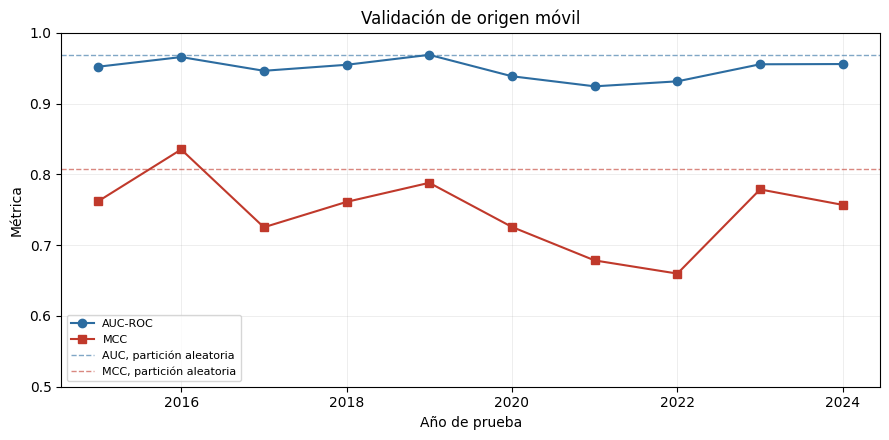

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(rdf.anio, rdf.AUC, 'o-', label='AUC-ROC', color='#2c6ca0')
ax.plot(rdf.anio, rdf.MCC, 's-', label='MCC', color='#c0392b')
ax.axhline(ref['AUC'], ls='--', lw=1, color='#2c6ca0', alpha=.6,
           label='AUC, partición aleatoria')
ax.axhline(ref['MCC'], ls='--', lw=1, color='#c0392b', alpha=.6,
           label='MCC, partición aleatoria')
ax.set_xlabel('Año de prueba'); ax.set_ylabel('Métrica')
ax.set_title('Validación de origen móvil')
ax.set_ylim(0.5, 1.0); ax.grid(alpha=.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()


## Validación espacial por bloques

El área de estudio se divide en una malla de 4×4. `GroupKFold` deja bloques completos
fuera del entrenamiento, de modo que la prueba ocurre en zonas geográficas no vistas.
Se evalúa con y sin coordenadas para separar lo que el modelo memoriza de la ubicación
de lo que aprende de las condiciones ambientales.


Bloques con datos: 16


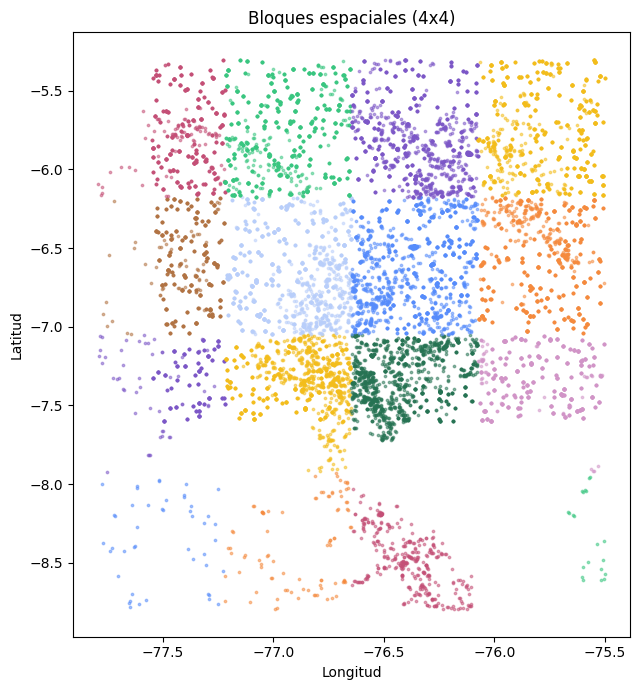

In [7]:
NB = 4
df['blk'] = (pd.cut(df.latitude, NB, labels=False).astype(str) + '_' +
             pd.cut(df.longitude, NB, labels=False).astype(str))
print('Bloques con datos:', df.blk.nunique())

fig, ax = plt.subplots(figsize=(6.5, 7))
for b, g in df.groupby('blk'):
    ax.scatter(g.longitude, g.latitude, s=3, alpha=.5, label=b)
ax.set_xlabel('Longitud'); ax.set_ylabel('Latitud')
ax.set_title(f'Bloques espaciales ({NB}x{NB})')
plt.tight_layout(); plt.show()


In [8]:
espacial = {}
for etq, feats in [('con coords', FEATS),
                   ('sin coords', [f for f in FEATS
                                   if f not in ('latitude', 'longitude')])]:
    folds = []
    for i, (a, b) in enumerate(GroupKFold(n_splits=5).split(
            df[feats], df['target'], groups=df.blk)):
        r = evaluar(df['target'].iloc[a], df[feats].iloc[a],
                    df['target'].iloc[b], df[feats].iloc[b])
        if r:
            r['fold'] = i + 1
            folds.append(r)
    espacial[etq] = pd.DataFrame(folds)
    e = espacial[etq]
    print(f"{etq:12s} Acc {e.Accuracy.mean():.4f}+/-{e.Accuracy.std():.4f}   "
          f"F1 {e.F1.mean():.4f}+/-{e.F1.std():.4f}   "
          f"AUC {e.AUC.mean():.4f}+/-{e.AUC.std():.4f}   "
          f"MCC {e.MCC.mean():.4f}+/-{e.MCC.std():.4f}")


con coords   Acc 0.8818+/-0.0371   F1 0.7910+/-0.0507   AUC 0.9362+/-0.0211   MCC 0.7067+/-0.0566
sin coords   Acc 0.8566+/-0.0310   F1 0.7505+/-0.0426   AUC 0.9193+/-0.0180   MCC 0.6518+/-0.0312


## Tabla resumen

In [9]:
def fila(esquema, d, sd=None):
    f = {'Esquema': esquema}
    for k in ['Accuracy', 'F1', 'AUC', 'MCC']:
        f[k] = f"{d[k]:.4f}" + (f" +/- {sd[k]:.4f}" if sd is not None else "")
    return f

filas = [fila('Partición aleatoria 85/15', ref)]
for etq in temporal:
    filas.append(fila(f'Holdout temporal ({etq})', temporal[etq]))
filas.append(fila('Origen móvil 2015-2024', rdf.mean(numeric_only=True),
                  rdf.std(numeric_only=True)))
for etq in espacial:
    e = espacial[etq]
    filas.append(fila(f'Bloques espaciales ({etq})',
                      e.mean(numeric_only=True), e.std(numeric_only=True)))

tabla = pd.DataFrame(filas)
print(tabla.to_string(index=False))
tabla.to_csv('validacion_independiente.csv', index=False)
print('\nGuardado: validacion_independiente.csv')


                        Esquema          Accuracy                F1               AUC               MCC
      Partición aleatoria 85/15            0.9197            0.8640            0.9681            0.8070
    Holdout temporal (con year)            0.8649            0.7986            0.9330            0.6970
    Holdout temporal (sin year)            0.8672            0.8046            0.9358            0.7041
         Origen móvil 2015-2024 0.8966 +/- 0.0252 0.8248 +/- 0.0459 0.9494 +/- 0.0143 0.7472 +/- 0.0519
Bloques espaciales (con coords) 0.8818 +/- 0.0371 0.7910 +/- 0.0507 0.9362 +/- 0.0211 0.7067 +/- 0.0566
Bloques espaciales (sin coords) 0.8566 +/- 0.0310 0.7505 +/- 0.0426 0.9193 +/- 0.0180 0.6518 +/- 0.0312

Guardado: validacion_independiente.csv
